In [24]:
!pip install -q imutils

import os
import pathlib
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import LabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from imutils import paths

from tensorflow.keras.utils import img_to_array
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Activation,
                                     Flatten, Dense, Dropout, Input)
from tensorflow.keras.optimizers import Adam

In [25]:
# Download and ensure clean manual extraction of the dataset
import shutil
import tarfile

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

# Define paths
cache_dir = pathlib.Path("/root/.keras/datasets")
data_dir = cache_dir / "flower_photos"

# Clean up any previously incomplete/broken cache folders
if not data_dir.exists():
    print("Target directory missing. Clearing datasets cache directory to force a clean extraction...")
    if cache_dir.exists():
        shutil.rmtree(cache_dir)

# Download the raw archive file without auto-extracting first to ensure it downloads cleanly
archive_path_str = tf.keras.utils.get_file(origin=dataset_url, extract=False)
archive_path = pathlib.Path(archive_path_str)

# Manually extract the archive to ensure the folder structure is correctly set up
print(f"Manually extracting archive {archive_path} to {cache_dir}...")
with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall(path=cache_dir)

print("Dataset folder:", data_dir)
for folder in sorted(os.listdir(data_dir)):
    path = data_dir / folder
    if path.is_dir():
        print(f"{folder:12s}: {len(os.listdir(path))} images")

Manually extracting archive /root/.keras/datasets/flower_photos.tgz to /root/.keras/datasets...


/tmp/ipykernel_376/2734251540.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=cache_dir)


Dataset folder: /root/.keras/datasets/flower_photos
daisy       : 633 images
dandelion   : 898 images
roses       : 641 images
sunflowers  : 699 images
tulips      : 799 images


In [26]:
# Set variables
height = 64
width = 64
depth = 3
classes = 5

In [27]:
# Loader function
def load_dataset(imagePaths, verbose=-1):
    data = []
    labels = []

    for (i, imagePath) in enumerate(imagePaths):
        image = cv2.imread(imagePath)
        if image is None:          # skip unreadable files
            continue

        label = imagePath.split(os.path.sep)[-2]   # label = folder name

        image = cv2.resize(image, (width, height))
        image = img_to_array(image)

        data.append(image)
        labels.append(label)

        if verbose > 0 and i > 0 and (i + 1) % verbose == 0:
            print("[INFO]: processed {}/{}".format(i + 1, len(imagePaths)))

    return (np.array(data), np.array(labels))

In [28]:
# Load the images
print("[INFO] loading images...")
imagePaths = list(paths.list_images(str(data_dir)))
(data, labels) = load_dataset(imagePaths, verbose=500)

print("Data shape:", data.shape)
print("Labels shape:", labels.shape)
print("Classes found:", np.unique(labels))

[INFO] loading images...
[INFO]: processed 500/3670
[INFO]: processed 1000/3670
[INFO]: processed 1500/3670
[INFO]: processed 2000/3670
[INFO]: processed 2500/3670
[INFO]: processed 3000/3670
[INFO]: processed 3500/3670
Data shape: (3670, 64, 64, 3)
Labels shape: (3670,)
Classes found: ['daisy' 'dandelion' 'roses' 'sunflowers' 'tulips']


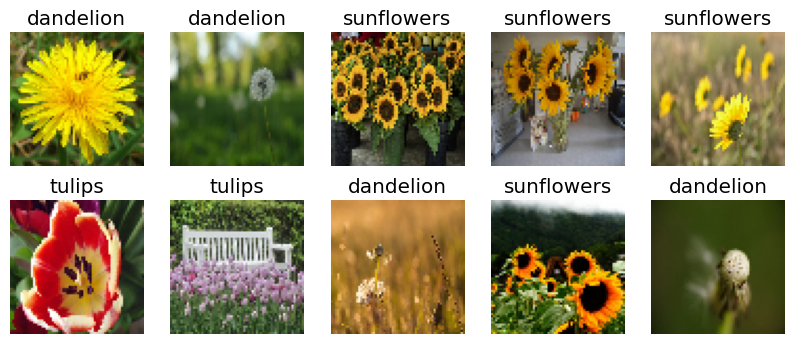

In [29]:
# Look at some images
plt.figure(figsize=(10, 4))
idx = np.random.choice(len(data), 10, replace=False)
for n, i in enumerate(idx):
    plt.subplot(2, 5, n + 1)
    plt.imshow(cv2.cvtColor(data[i].astype("uint8"), cv2.COLOR_BGR2RGB))
    plt.title(labels[i])
    plt.axis("off")
plt.show()

In [30]:
# Scale, split and encode
# Scale pixel intensities to [0, 1]
data = data.astype("float32") / 255.0

# 75% train / 25% test (matches the code in the handout)
(trainX, testX, trainY, testY) = train_test_split(
    data, labels, test_size=0.25, random_state=42, stratify=labels)

# Fit the binarizer on TRAIN labels only, reuse it for TEST labels
lb = LabelBinarizer()
trainY = lb.fit_transform(trainY)
testY = lb.transform(testY)

print("Train:", trainX.shape, trainY.shape)
print("Test: ", testX.shape, testY.shape)
print("Class order:", lb.classes_)

Train: (2752, 64, 64, 3) (2752, 5)
Test:  (918, 64, 64, 3) (918, 5)
Class order: ['daisy' 'dandelion' 'roses' 'sunflowers' 'tulips']


In [31]:
# Build the model
model = Sequential()
model.add(Input(shape=(height, width, depth)))

# Block 1
model.add(Conv2D(32, (3, 3), padding="same"))
model.add(Activation("relu"))
model.add(MaxPooling2D((2, 2)))

# Block 2
model.add(Conv2D(64, (3, 3), padding="same"))
model.add(Activation("relu"))
model.add(MaxPooling2D((2, 2)))

# Block 3
model.add(Conv2D(128, (3, 3), padding="same"))
model.add(Activation("relu"))
model.add(MaxPooling2D((2, 2)))

# Classifier
model.add(Flatten())
model.add(Dense(128, activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(classes))
model.add(Activation("softmax"))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 5)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,597 (4.36 MB)

 Trainable params: 1,142,597 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
# Compile and train
epochs = 30

model.compile(loss="categorical_crossentropy",
              optimizer=Adam(learning_rate=0.001),
              metrics=["accuracy"])

print("[INFO] training network...")
H = model.fit(trainX, trainY,
              validation_data=(testX, testY),
              batch_size=32, epochs=epochs, verbose=1)

[INFO] training network...
Epoch 1/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 82ms/step - accuracy: 0.3448 - loss: 1.4577 - val_accuracy: 0.4662 - val_loss: 1.2151
Epoch 2/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5015 - loss: 1.1967 - val_accuracy: 0.5752 - val_loss: 1.0623
Epoch 3/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5890 - loss: 1.0482 - val_accuracy: 0.5806 - val_loss: 1.0580
Epoch 4/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6315 - loss: 0.9495 - val_accuracy: 0.6503 - val_loss: 0.8874
Epoch 5/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6617 - loss: 0.8756 - val_accuracy: 0.6885 - val_loss: 0.8277
Epoch 6/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6988 - loss: 0.7923 - val_accuracy: 0.6656 - val_loss: 0.8639
Epoch 7/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7260 - loss: 0.7154 - val_accuracy: 0.6863 - val_loss: 0.7819
Epoch 8/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7536 - loss: 0.662

In [33]:
# Evaluate
print("[INFO] evaluating network...")
predictions = model.predict(testX, batch_size=32)
print(classification_report(testY.argmax(axis=1),
                            predictions.argmax(axis=1),
                            target_names=lb.classes_))

test_loss, test_acc = model.evaluate(testX, testY, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

[INFO] evaluating network...
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step
              precision    recall  f1-score   support

       daisy       0.72      0.73      0.72       158
   dandelion       0.79      0.72      0.76       225
       roses       0.60      0.66      0.63       160
  sunflowers       0.78      0.84      0.81       175
      tulips       0.65      0.61      0.63       200

    accuracy                           0.71       918
   macro avg       0.71      0.71      0.71       918
weighted avg       0.71      0.71      0.71       918

Test loss: 1.7609 | Test accuracy: 0.7102


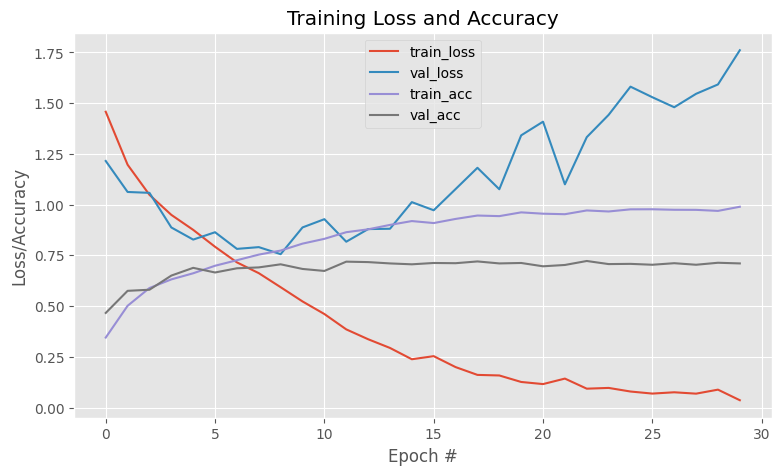

In [34]:
# Plot loss and accuracy
plt.style.use("ggplot")
plt.figure(figsize=(9, 5))
plt.plot(np.arange(0, epochs), H.history["loss"], label="train_loss")
plt.plot(np.arange(0, epochs), H.history["val_loss"], label="val_loss")
plt.plot(np.arange(0, epochs), H.history["accuracy"], label="train_acc")
plt.plot(np.arange(0, epochs), H.history["val_accuracy"], label="val_acc")
plt.title("Training Loss and Accuracy")
plt.xlabel("Epoch #")
plt.ylabel("Loss/Accuracy")
plt.legend()
plt.show()

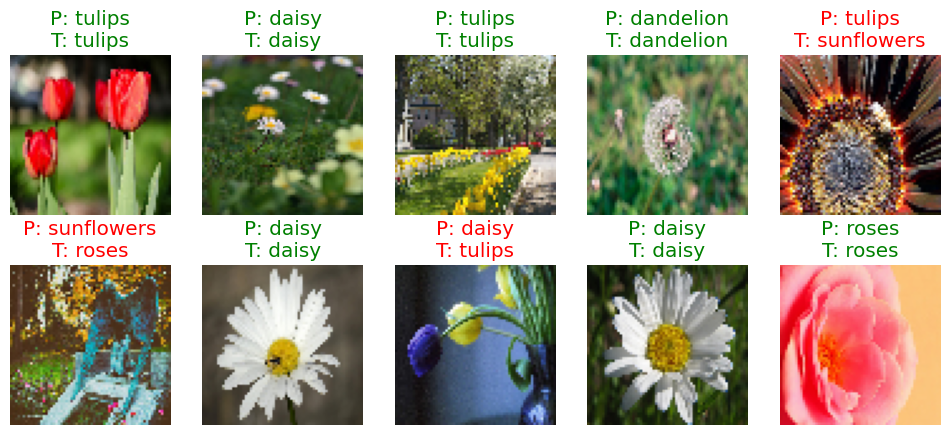

In [35]:
# : Test predictions on sample images
plt.figure(figsize=(12, 5))
idx = np.random.choice(len(testX), 10, replace=False)
for n, i in enumerate(idx):
    pred = lb.classes_[predictions[i].argmax()]
    true = lb.classes_[testY[i].argmax()]
    plt.subplot(2, 5, n + 1)
    plt.imshow(cv2.cvtColor((testX[i] * 255).astype("uint8"), cv2.COLOR_BGR2RGB))
    plt.title(f"P: {pred}\nT: {true}", color="green" if pred == true else "red")
    plt.axis("off")
plt.show()


In [ ]:
# Optional: Reduce overfitting (data augmentation)
from tensorflow.keras.preprocessing.image import ImageDataGenerator

aug = ImageDataGenerator(rotation_range=20, width_shift_range=0.1,
                         height_shift_range=0.1, horizontal_flip=True,
                         zoom_range=0.15)

epochs = 40
model.compile(loss="categorical_crossentropy",
              optimizer=Adam(learning_rate=0.001), metrics=["accuracy"])

H = model.fit(aug.flow(trainX, trainY, batch_size=32),
              validation_data=(testX, testY),
              epochs=epochs, verbose=1)

Epoch 1/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 11s 86ms/step - accuracy: 0.7191 - loss: 0.8909 - val_accuracy: 0.6993 - val_loss: 0.8742
Epoch 2/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 6s 62ms/step - accuracy: 0.7598 - loss: 0.6828 - val_accuracy: 0.7397 - val_loss: 0.7679
Epoch 3/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.7653 - loss: 0.6550 - val_accuracy: 0.7222 - val_loss: 0.8863
Epoch 4/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.7765 - loss: 0.6108 - val_accuracy: 0.7277 - val_loss: 0.7775
Epoch 5/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.7769 - loss: 0.6147 - val_accuracy: 0.7331 - val_loss: 0.7437
Epoch 6/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.7674 - loss: 0.6305 - val_accuracy: 0.7516 - val_loss: 0.6910
Epoch 7/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.7776 - loss: 0.5867 - val_accuracy: 0.7102 - val_loss: 0.8422
Epoch 8/40
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.7874 - loss: 0.5682 - val_accuracy: 0.7593 - 